# Семинар: Кластеризация на Python

**Цель семинара:** На практике познакомиться с основными алгоритмами кластеризации, научиться подбирать гиперпараметры, оценивать качество без учителя и интерпретировать результаты.

**Что мы сделаем:**
1. **KMeans и метрики:** Научимся выбирать `k` через метод локтя и силуэт.
2. **Нелинейные данные:** Увидим, почему KMeans пасует перед полумесяцами, и как спасают DBSCAN и Spectral.
3. **Иерархическая кластеризация:** Построим дендрограмму.
4. **GMM:** Посмотрим на мягкую кластеризацию (вероятности).
5. **Реальный кейс (Wine):** Сделаем полный пайплайн с визуализацией через PCA и интерпретацией профилей кластеров.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, make_moons, make_circles, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, davies_bouldin_score

# Алгоритмы
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, SpectralClustering
from sklearn.mixture import GaussianMixture

# Для дендрограммы
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Настройки графиков
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')
np.random.seed(42)

## Часть 1. KMeans и выбор количества кластеров

Сгенерируем сферические данные (`make_blobs`). 
**Важно:** для KMeans данные нужно масштабировать!

In [ ]:
# Генерируем 300 точек, 4 признака, 4 центра
X_blobs, y_true_blobs = make_blobs(n_samples=300, centers=4, n_features=4, random_state=42)

# Масштабирование (обязательно пригодится для KMeans)
scaler = StandardScaler()
X_blobs_scaled = scaler.fit_transform(X_blobs)

print(f"Форма данных: {X_blobs_scaled.shape}")

Форма данных: (300, 4)


### Метод локтя и Силуэт
Будем перебирать `k` от 2 до 10 и смотреть на `inertia_` (внутрикластерное расстояние) и `silhouette_score`.

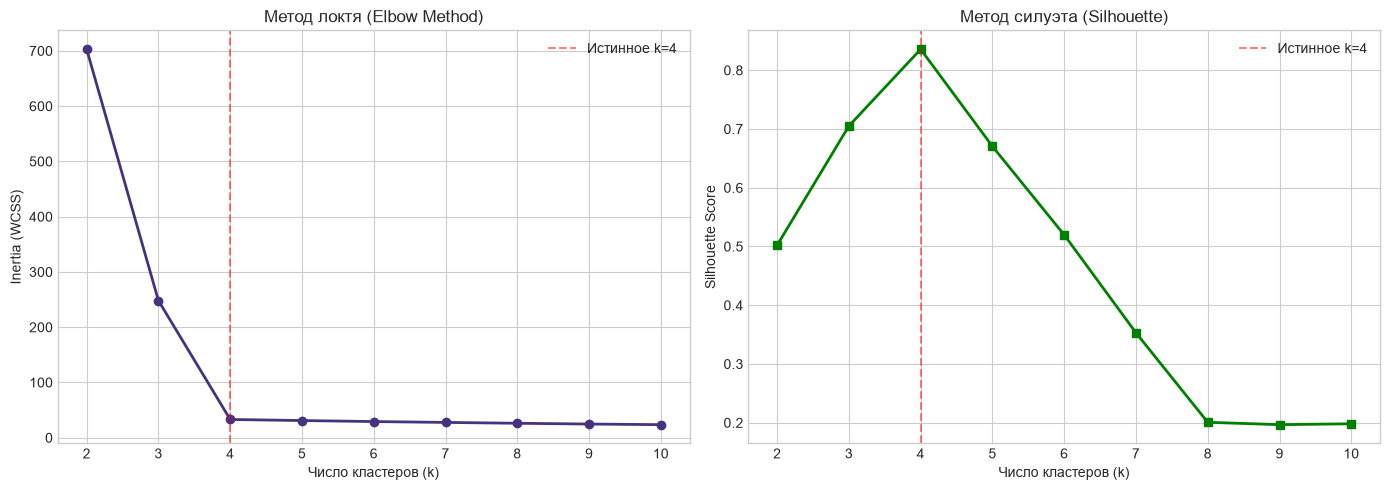

In [3]:
inertias = []
silhouettes = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(X_blobs_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_blobs_scaled, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# График локтя
ax1.plot(K_range, inertias, marker='o', linewidth=2)
ax1.set_title('Метод локтя (Elbow Method)')
ax1.set_xlabel('Число кластеров (k)')
ax1.set_ylabel('Inertia (WCSS)')
ax1.axvline(x=4, color='red', linestyle='--', alpha=0.5, label='Истинное k=4')
ax1.legend()

# График силуэта
ax2.plot(K_range, silhouettes, marker='s', color='green', linewidth=2)
ax2.set_title('Метод силуэта (Silhouette)')
ax2.set_xlabel('Число кластеров (k)')
ax2.set_ylabel('Silhouette Score')
ax2.axvline(x=4, color='red', linestyle='--', alpha=0.5, label='Истинное k=4')
ax2.legend()

plt.tight_layout()
plt.show()

Оба метода (локоть и силуэт) указывают на `k=4`, что совпадает с истиной. Силуэт > 0.8 означает очень хорошую структуру кластеров.

## Часть 2. Нелинейные структуры: KMeans vs DBSCAN vs Spectral

Сгенерируем данные в виде двух «полумесяцев» (`make_moons`). Здесь KMeans провалится, а плотностные и графовые методы — нет.

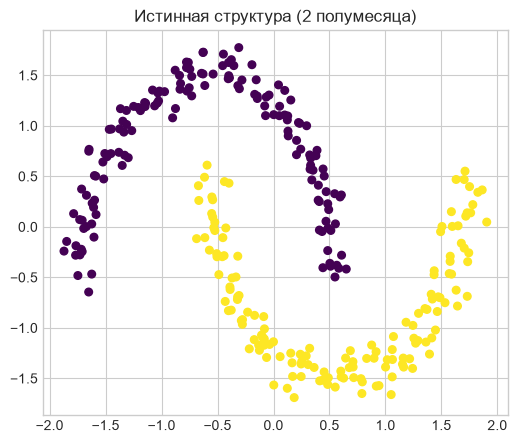

In [4]:
X_moons, y_true_moons = make_moons(n_samples=300, noise=0.06, random_state=42)
X_moons_scaled = StandardScaler().fit_transform(X_moons)

plt.figure(figsize=(6, 5))
plt.scatter(X_moons_scaled[:, 0], X_moons_scaled[:, 1], c=y_true_moons, cmap='viridis', s=30)
plt.title('Истинная структура (2 полумесяца)')
plt.show()

/opt/anaconda3/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


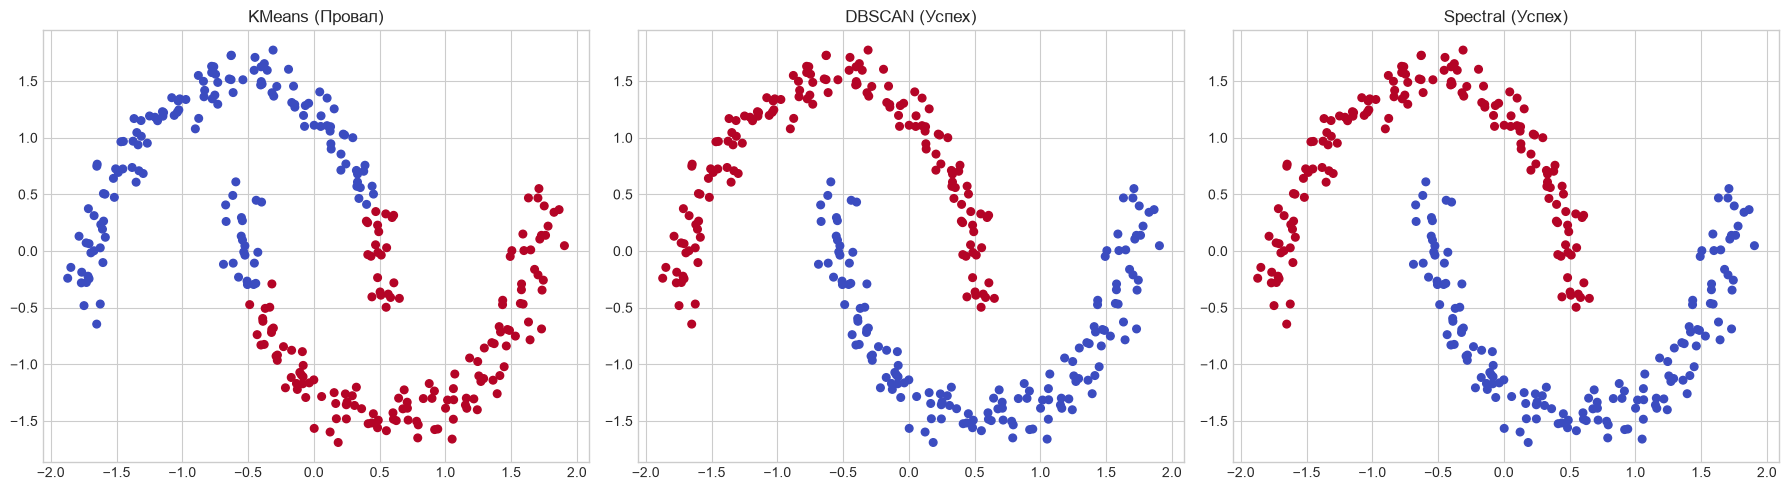

In [5]:
# 1. KMeans
km_moons = KMeans(n_clusters=2, random_state=42)
labels_km = km_moons.fit_predict(X_moons_scaled)

# 2. DBSCAN
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_db = dbscan.fit_predict(X_moons_scaled)

# 3. Spectral Clustering (k-NN граф)
spectral = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', random_state=42)
labels_spec = spectral.fit_predict(X_moons_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X_moons_scaled[:, 0], X_moons_scaled[:, 1], c=labels_km, cmap='coolwarm', s=30)
axes[0].set_title('KMeans (Провал)')

axes[1].scatter(X_moons_scaled[:, 0], X_moons_scaled[:, 1], c=labels_db, cmap='coolwarm', s=30)
axes[1].set_title('DBSCAN (Успех)')

axes[2].scatter(X_moons_scaled[:, 0], X_moons_scaled[:, 1], c=labels_spec, cmap='coolwarm', s=30)
axes[2].set_title('Spectral (Успех)')

plt.tight_layout()
plt.show()

KMeans провел прямую линию, потому что он ищет сферические кластеры. DBSCAN нашел кластеры по плотности, а Spectral — по связям в графе соседей.

**Обратите внимание:** DBSCAN может выявлять шум (метка `-1`). На графике с шумом точки могут быть окрашены в отдельный цвет.

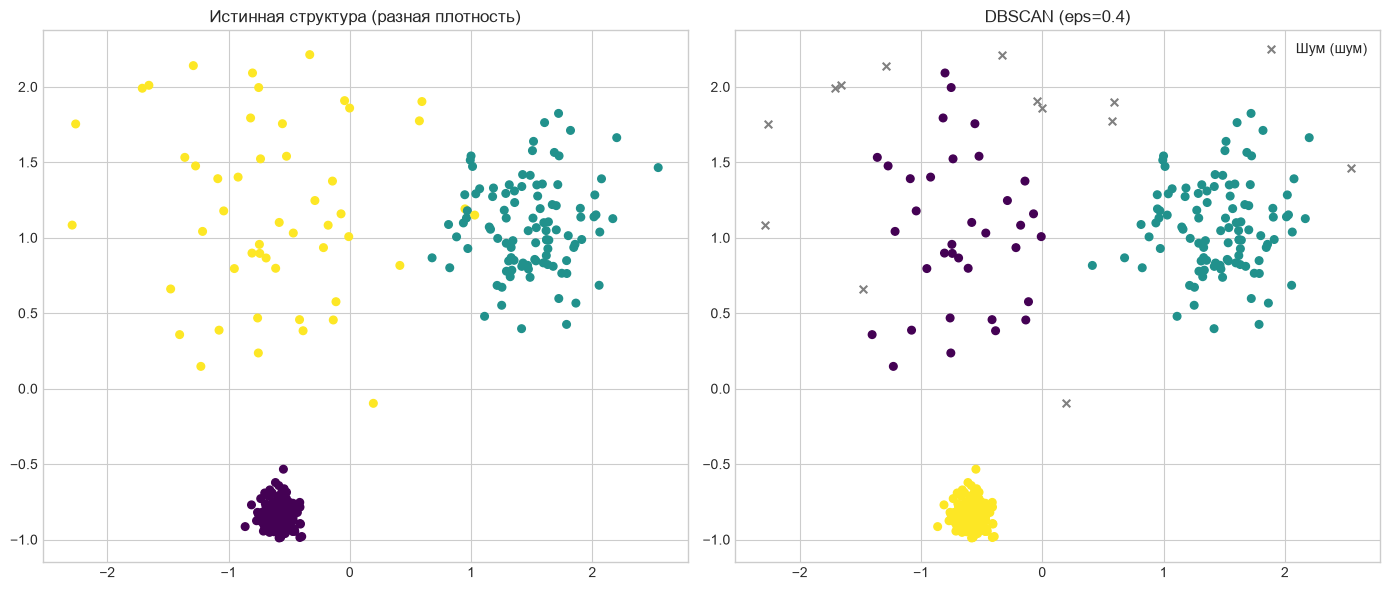

In [45]:
# DBSCAN и кластеры с разной плотностью
# Генерируем три кластера с разной степенью разброса (плотностью)
X_dens, y_dens = make_blobs(
    n_samples=[200, 100, 50], # Разное число точек
    centers=[[0, 0], [5, 5], [0, 5]],
    cluster_std=[0.2, 0.8, 1.5], # Разный разброс (плотность)
    random_state=42
)
X_dens_scaled = StandardScaler().fit_transform(X_dens)

# DBSCAN с фиксированным eps
db_dens = DBSCAN(eps=0.4, min_samples=5)
labels_db_dens = db_dens.fit_predict(X_dens_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(X_dens_scaled[:, 0], X_dens_scaled[:, 1], c=y_dens, cmap='viridis', s=30)
axes[0].set_title('Истинная структура (разная плотность)')

# Отображаем DBSCAN, выделяя шум
noise_mask = labels_db_dens == -1
axes[1].scatter(X_dens_scaled[~noise_mask, 0], X_dens_scaled[~noise_mask, 1], 
                c=labels_db_dens[~noise_mask], cmap='viridis', s=30)
if noise_mask.any():
    axes[1].scatter(X_dens_scaled[noise_mask, 0], X_dens_scaled[noise_mask, 1], 
                    c='gray', marker='x', s=30, label='Шум (шум)')
axes[1].set_title('DBSCAN (eps=0.4)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [14]:
# Генерируем концентрические окружности
X_circles, y_true_circles = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=42)
X_circles_scaled = StandardScaler().fit_transform(X_circles)

In [15]:
# 1. KMeans
km_circ = KMeans(n_clusters=2, random_state=42)
labels_km_circ = km_circ.fit_predict(X_circles_scaled)

In [33]:
# 2. DBSCAN
# Здесь важно подобрать eps: если он слишком большой, алгоритм объединит оба круга, 
# если слишком маленький — найдет много шума.
dbscan_circ = DBSCAN(eps=0.3, min_samples=5)
labels_db_circ = dbscan_circ.fit_predict(X_circles_scaled)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/var/folders/vb/ln0by8yd5g188n3xwgtwx5dr0000gn/T/ipykernel_43920/1718116459.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[2].legend()


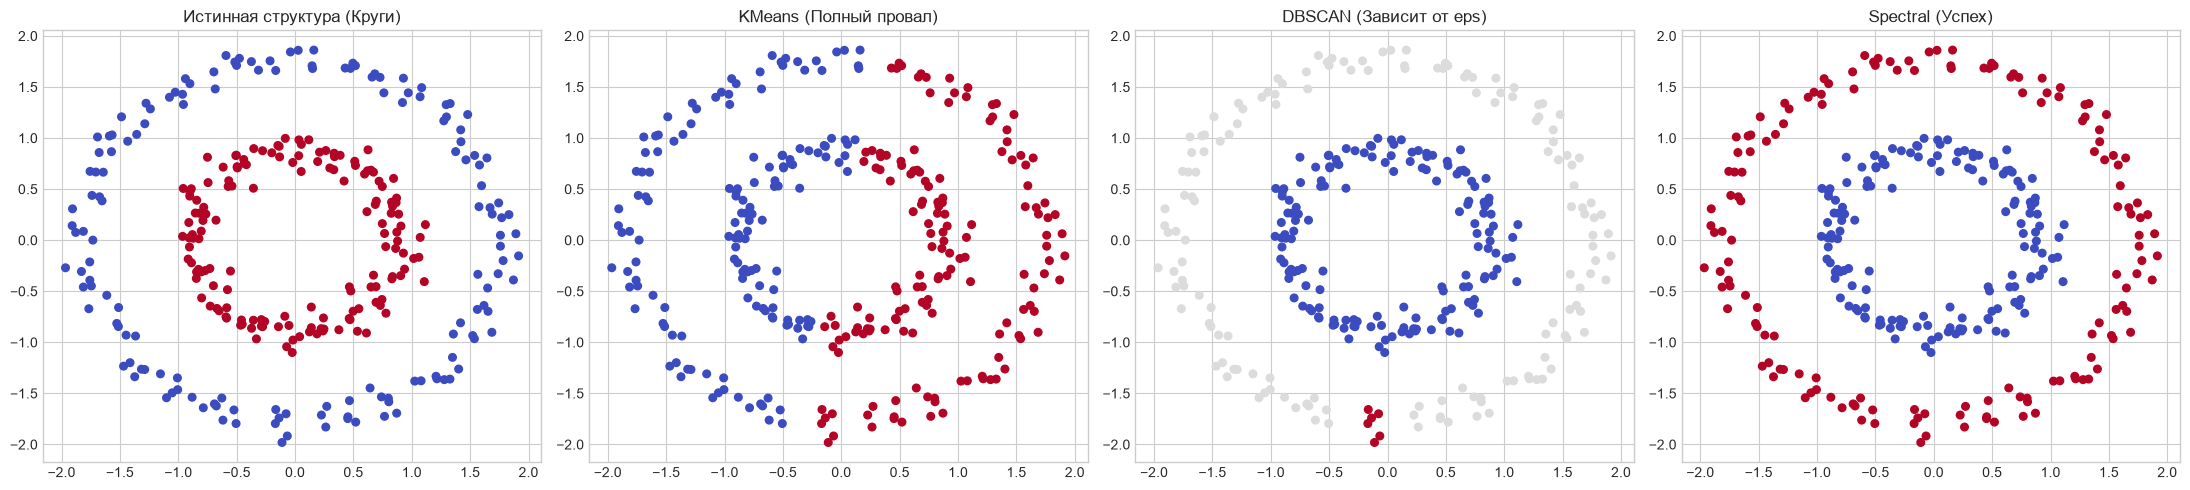

In [34]:
# 3. Spectral Clustering
# Отлично работает на графах, где важна связность, а не расстояние до центра
spectral_circ = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', random_state=42)
labels_spec_circ = spectral_circ.fit_predict(X_circles_scaled)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# Истина
axes[0].scatter(X_circles_scaled[:, 0], X_circles_scaled[:, 1], c=y_true_circles, cmap='coolwarm', s=30)
axes[0].set_title('Истинная структура (Круги)')

# KMeans
axes[1].scatter(X_circles_scaled[:, 0], X_circles_scaled[:, 1], c=labels_km_circ, cmap='coolwarm', s=30)
axes[1].set_title('KMeans (Полный провал)')

# DBSCAN
# Проверим, есть ли шум (метка -1)
noise_mask = labels_db_circ == -1
axes[2].scatter(X_circles_scaled[~noise_mask, 0], X_circles_scaled[~noise_mask, 1], 
                c=labels_db_circ[~noise_mask], cmap='coolwarm', s=30)
if noise_mask.any():
    axes[2].scatter(X_circles_scaled[noise_mask, 0], X_circles_scaled[noise_mask, 1], 
                    c='gray', marker='x', s=30, label='Шум')
axes[2].set_title('DBSCAN (Зависит от eps)')
axes[2].legend()

# Spectral
axes[3].scatter(X_circles_scaled[:, 0], X_circles_scaled[:, 1], c=labels_spec_circ, cmap='coolwarm', s=30)
axes[3].set_title('Spectral (Успех)')

plt.tight_layout()
plt.show()

/var/folders/vb/ln0by8yd5g188n3xwgtwx5dr0000gn/T/ipykernel_43920/2295367640.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[2].legend()


<Figure size 640x480 with 0 Axes>

## Часть 3. Иерархическая кластеризация и дендрограмма
Построим дерево слияний для датасета `Iris` (возьмем только 2 признака для наглядности).

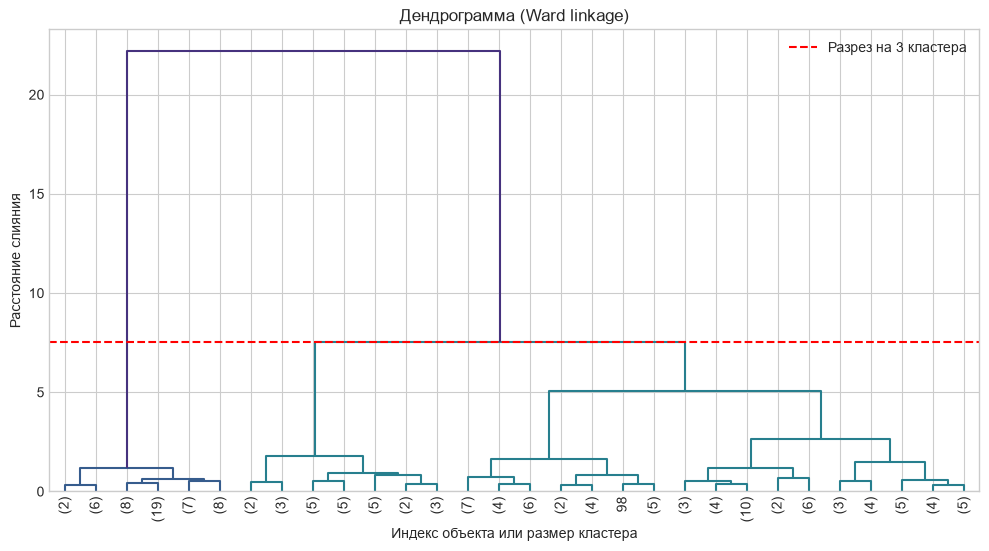

In [6]:
from sklearn.datasets import load_iris
iris = load_iris()
# Берем только 2 признака (длина и ширина лепестка)
X_iris = iris.data[:, 2:4]
X_iris_scaled = StandardScaler().fit_transform(X_iris)

# Строим матрицу связей (linkage)
Z = linkage(X_iris_scaled, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=10)
plt.title('Дендрограмма (Ward linkage)')
plt.xlabel('Индекс объекта или размер кластера')
plt.ylabel('Расстояние слияния')
# Проведем линию разреза для 3 кластеров
plt.axhline(y=Z[-2, 2], color='red', linestyle='--', label='Разрез на 3 кластера')
plt.legend()
plt.show()

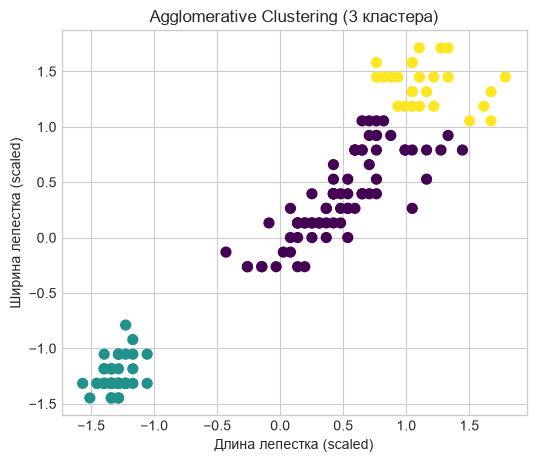

In [7]:
# Прямое использование AgglomerativeClustering
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_agg = agg.fit_predict(X_iris_scaled)

plt.figure(figsize=(6, 5))
plt.scatter(X_iris_scaled[:, 0], X_iris_scaled[:, 1], c=labels_agg, cmap='viridis', s=50)
plt.title('Agglomerative Clustering (3 кластера)')
plt.xlabel('Длина лепестка (scaled)')
plt.ylabel('Ширина лепестка (scaled)')
plt.show()

## Часть 4. GMM (Gaussian Mixture Model)
Посмотрим на «мягкую» кластеризацию. GMM выдает вероятности принадлежности к каждому кластеру.

Точка 0 имеет вероятности: [0. 1. 0. 0.]
Уверенность модели в этой точке: 1.00


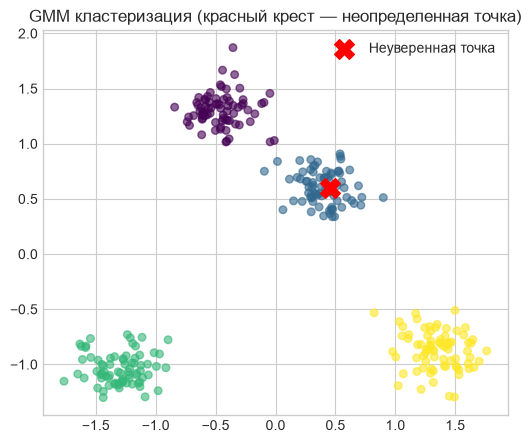

In [8]:
gmm = GaussianMixture(n_components=4, covariance_type='full', random_state=42)
gmm.fit(X_blobs_scaled)

# Предсказанные метки (hard)
labels_gmm = gmm.predict(X_blobs_scaled)
# Вероятности (soft)
probs_gmm = gmm.predict_proba(X_blobs_scaled)

# Найдем точку с наибольшей неопределенностью (вероятности близки к 0.5)
uncertainty = 1 - np.max(probs_gmm, axis=1)
idx_uncertain = np.argmax(uncertainty)

print(f"Точка {idx_uncertain} имеет вероятности: {probs_gmm[idx_uncertain].round(2)}")
print(f"Уверенность модели в этой точке: {1 - uncertainty[idx_uncertain]:.2f}")

plt.figure(figsize=(6, 5))
plt.scatter(X_blobs_scaled[:, 0], X_blobs_scaled[:, 1], c=labels_gmm, cmap='viridis', s=30, alpha=0.6)
plt.scatter(X_blobs_scaled[idx_uncertain, 0], X_blobs_scaled[idx_uncertain, 1], 
            color='red', marker='X', s=200, label='Неуверенная точка')
plt.title('GMM кластеризация (красный крест — неопределенная точка)')
plt.legend()
plt.show()

## Часть 5. Датасет Wine и интерпретация

Мы загрузим датасет Wine (химический анализ вин). В нем 13 признаков и 3 истинных класса (сорта винограда). Мы сделаем вид, что меток у нас нет, проведем кластеризацию и попробуем интерпретировать результаты.

Silhouette Score: 0.285
Adjusted Rand Index (сравнение с истиной): 0.897


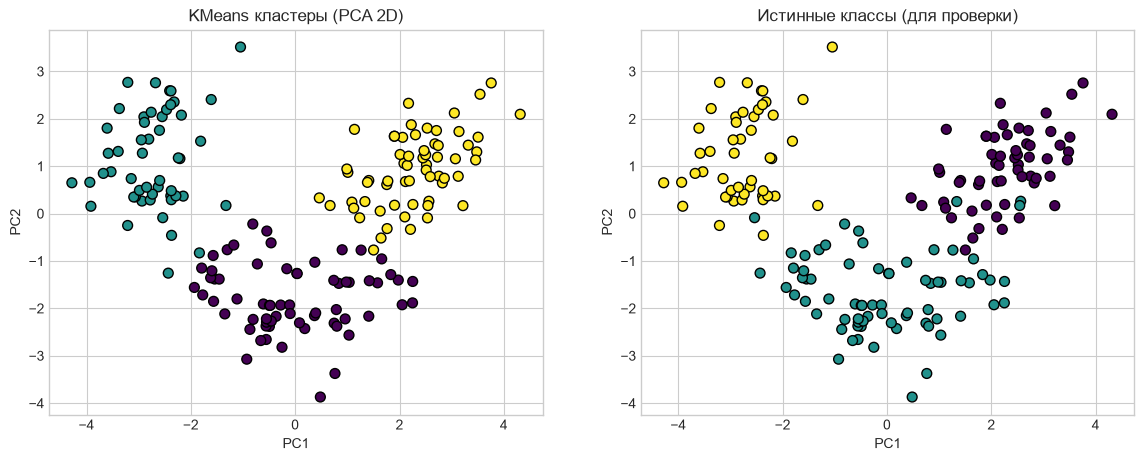

In [9]:
wine = load_wine()
X_wine = wine.data
y_true_wine = wine.target

# Обязательное масштабирование
X_wine_scaled = StandardScaler().fit_transform(X_wine)

# Понижаем размерность до 2D для визуализации
pca = PCA(n_components=2, random_state=42)
X_wine_pca = pca.fit_transform(X_wine_scaled)

# Кластеризация KMeans
km_wine = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_wine = km_wine.fit_predict(X_wine_scaled)

print(f"Silhouette Score: {silhouette_score(X_wine_scaled, labels_wine):.3f}")
print(f"Adjusted Rand Index (сравнение с истиной): {adjusted_rand_score(y_true_wine, labels_wine):.3f}")

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=labels_wine, cmap='viridis', s=50, edgecolor='k')
plt.title('KMeans кластеры (PCA 2D)')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.subplot(1, 2, 2)
plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=y_true_wine, cmap='viridis', s=50, edgecolor='k')
plt.title('Истинные классы (для проверки)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

### Интерпретация профилей кластеров
Добавим метки кластеров к исходным данным и посмотрим на средние значения признаков.

In [10]:
# Создаем DataFrame
df_wine = pd.DataFrame(X_wine, columns=wine.feature_names)
df_wine['cluster'] = labels_wine

# Считаем средние по кластерам
cluster_profiles = df_wine.groupby('cluster').mean()

# Выведем признаки с наибольшей разницей между кластерами
feature_variance = cluster_profiles.var(axis=0).sort_values(ascending=False)
print("Топ-5 маркерных признаков (наибольшая разница между кластерами):")
print(feature_variance.head(5))

Топ-5 маркерных признаков (наибольшая разница между кластерами):
proline              98590.895229
magnesium               58.930766
color_intensity          4.581124
alcalinity_of_ash        3.737362
flavanoids               1.199341
dtype: float64


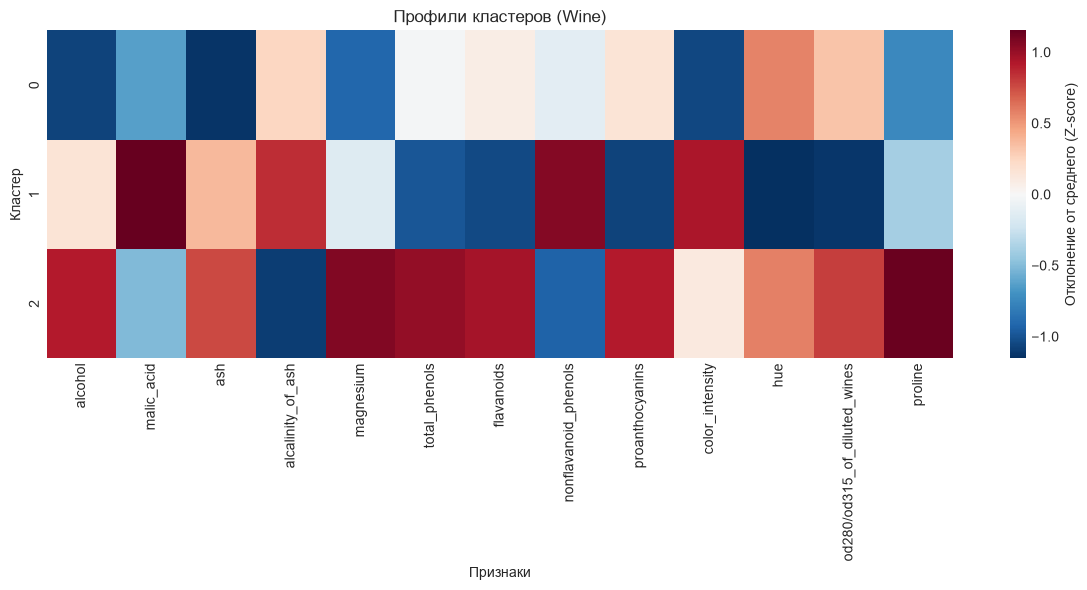

In [ ]:
# Визуализация профилей (тепловая карта)
plt.figure(figsize=(12, 6))
# Нормализуем профили для отображения Z-score по признакам
profiles_norm = (cluster_profiles - cluster_profiles.mean()) / cluster_profiles.std()

sns.heatmap(profiles_norm, cmap='RdBu_r', center=0, annot=False, cbar_kws={'label': 'Отклонение от среднего (Z-score)'})
plt.title('Профили кластеров (Wine)')
plt.xlabel('Признаки')
plt.ylabel('Кластер')
plt.tight_layout()
plt.show()

### Сжатие изображения

In [36]:
%pip install scikit-image --quiet

Note: you may need to restart the kernel to use updated packages.


In [38]:
from skimage import data
from skimage.transform import rescale

In [57]:
# Загружаем тестовое изображение
img = rescale(data.astronaut(), scale=0.5, channel_axis=-1)
h, w, c = img.shape

In [58]:
# Превращаем картинку в таблицу: каждый пиксель — это объект с 3 признаками (R, G, B)
X_pixels = img.reshape(-1, 3)
print(f"Форма таблицы пикселей: {X_pixels.shape}")

Форма таблицы пикселей: (65536, 3)


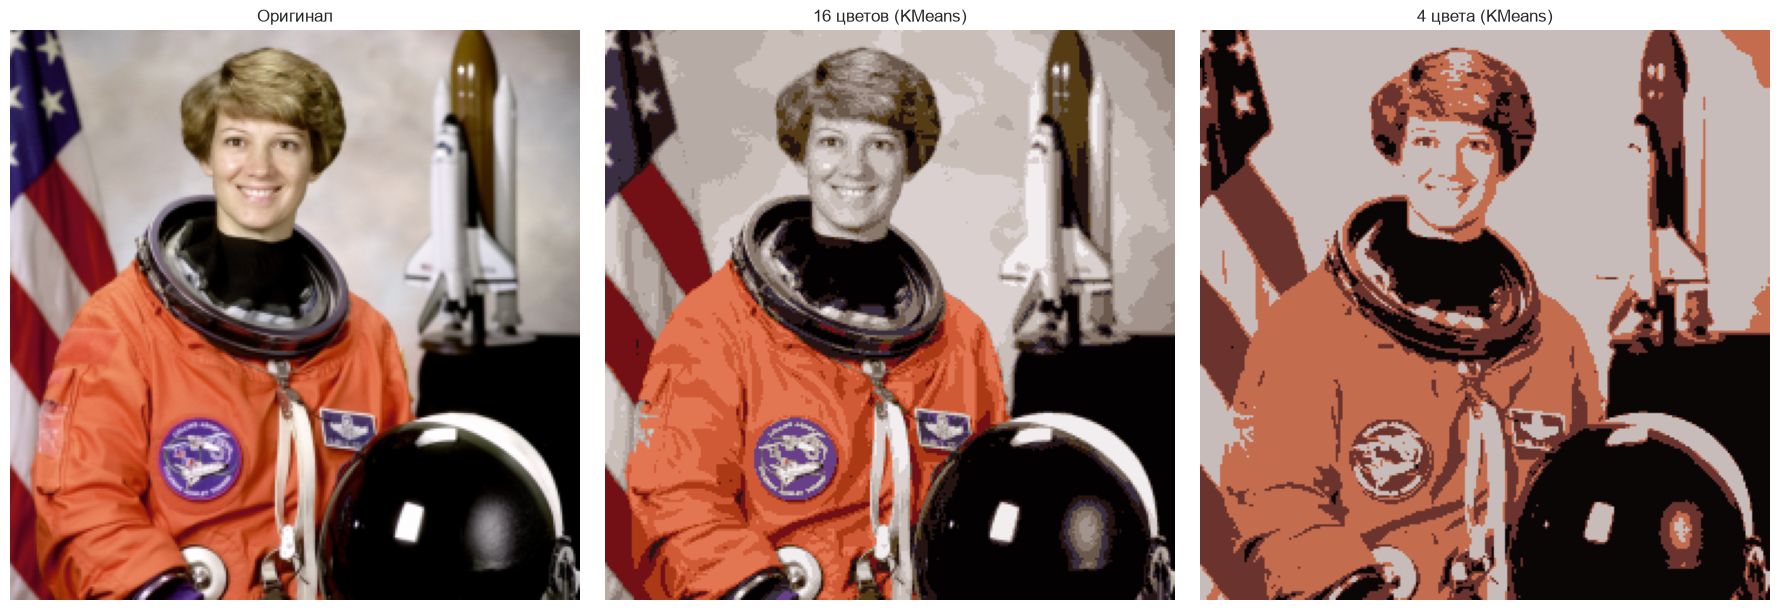

In [59]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Оригинал
axes[0].imshow(img)
axes[0].set_title('Оригинал')
axes[0].axis('off')

# KMeans на 16 цветов
km_16 = KMeans(n_clusters=16, random_state=42, n_init=5)
labels_16 = km_16.fit_predict(X_pixels)
# Заменяем каждый пиксель на цвет его центроида
img_16 = km_16.cluster_centers_[labels_16].reshape(h, w, 3)

axes[1].imshow(np.clip(img_16, 0, 1))
axes[1].set_title('16 цветов (KMeans)')
axes[1].axis('off')

# KMeans на 4 цвета
km_4 = KMeans(n_clusters=4, random_state=42, n_init=5)
labels_4 = km_4.fit_predict(X_pixels)
img_4 = km_4.cluster_centers_[labels_4].reshape(h, w, 3)

axes[2].imshow(np.clip(img_4, 0, 1))
axes[2].set_title('4 цвета (KMeans)')
axes[2].axis('off')

plt.tight_layout()
plt.show()